# Single layer — a neutral-surface strain prior

One fit of the single-layer analogue model, made twice with the same data, basis and training:

1. **geometry only**, as in `03b_single_layer_fit`;
2. **geometry plus a neutral-surface prior**: the Hencky strain energy ‖ln U‖²
   (with F = RU) is penalised in a thin band along the middle of the competent layer
   (H2–H3), so that surface has no finite strain, as the neutral surface of ideal
   tangential longitudinal strain: circles there stay circles. No strain markers are used.

Both are scored against all 100 digitised strain markers, none of which either
fit sees, and against those held out in `03b` (where the others constrain the
fit). Reads the settings `03b` saves (`results/fit_settings.json`), so the basis and
training match the ensembles of `03c`. Saves `results/strain_prior.npz`; the figure is
made in `03f_single_layer_strain_prior_figures`.

## Setup

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
import torch

import curlew
from curlew.core import CSet, HSet
from curlew.kinematics.euler import euler_velocity
from curlew.kinematics.constraints import HenckyStrain
from curlew.geometry import Grid
from curlew.geology import restore

import sys
sys.path.insert(0, str(Path("..").resolve()))                      # publication/: figstyle
import figstyle
import single_layer_inputs as sli

figstyle.apply()
curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 2

DATA_DIR = Path("data")
RES_DIR = Path("./results")
RES_DIR.mkdir(parents=True, exist_ok=True)

## Data

The contacts and bedding that `03b` fits, in its frame (H0 at the top; H2 and H3
bound the competent layer). Strain is shown in the competent layer as each fit draws it, not between the digitised
traces: `N_ACROSS` rows of `N_ALONG` points, from the fit's H2 to its H3 (built after each fit,
below).

In [2]:
truth = sli.load_truth(DATA_DIR)
obs = sli.load_observations(truth, DATA_DIR)
horizons_full, horizons, gp, gv = truth["horizons_full"], obs["horizons"], obs["gp"], obs["gv"]
iq_pairs = [(horizons[i], horizons[i + 1], ">") for i in range(len(horizons) - 1)]
anchor = torch.tensor([0.0, 0.0], dtype=curlew.dtype, device=curlew.device)

N_ALONG, N_ACROSS = 140, 9
LAYER_T = (0.02, 0.98)                  # the fill, as fractions of the layer's thickness from H2

pts = np.vstack(horizons_full)
extent = 1.15 * (pts.max(axis=0) - pts.min(axis=0))
G = Grid(tuple(extent), step=(4.0, 4.0), center=(0.0, 0.0), sampleArgs=dict(N=4096))
grid_tensor = torch.as_tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)
print(f"contacts {sum(map(len, horizons))} | bedding {len(gp)}")

contacts 60 | bedding 10


## The two fits

The settings of `03b`, read from `results/fit_settings.json` (one member, seed `FOURIER_SEED`). The prior is curlew's
`HenckyStrain`, evaluated in the band `PRIOR_BAND` of the competent layer's thickness (from H2), redrawn at
every step between the fit's own restored H2 and H3 contacts (`horizons=COMPETENT`), so it follows
the layer as the fit draws it and uses only the contacts the fit sees, with a string weight
balanced against its value once that reaches `PRIOR_FLOOR`, so it switches on only after the
data have bent the layer.

In [4]:
import json
S = json.loads((RES_DIR / "fit_settings.json").read_text())     # written by 03b
FOURIER_SEED = S["fourier_seed"]
N_FEATURES, N_DIRECTIONS = S["n_features"], S["n_directions"]
BAND = tuple(S["length_scale_range"])                 # wavelength band (model units), from the data
EPOCHS = S["epochs"] + 1000                                     # More epochs to get the prior to converge
WEIGHTS = S["weights"]
IQ_SAMPLES = S["iq_samples"]
LR_ADAM = S["lr_adam"]                 # Adam rate for the phases and biases
LR_SGD, AMP_MOMENTUM = S["lr_sgd"], S["amp_momentum"]   # gradient descent with momentum for the amplitudes
print(f"basis: {N_FEATURES} modes on {N_DIRECTIONS} rays, band {BAND[0]:.0f}-{BAND[1]:.0f}, {EPOCHS} iterations")

PRIOR_WEIGHT = "1e-3"
PRIOR_FLOOR = 1e-2                      # the weight is balanced once the prior's loss, ½(ln q)², reaches this (axial ratio ~1.15)
PRIOR_BAND = (0.45, 0.55)               # the middle tenth of the competent layer
PRIOR_ALONG, PRIOR_ACROSS = 100, 1       # prior points along and across that band


def fit(prior):
    torch.manual_seed(FOURIER_SEED)
    velocity = euler_velocity(2, n_features=N_FEATURES, n_directions=N_DIRECTIONS, length_scale_range=BAND,
                              stream="alpha", activation="cubic", seed=FOURIER_SEED, energy_normalised=True)
    constraints = [HenckyStrain(PRIOR_WEIGHT, horizons=sli.COMPETENT, n_along=PRIOR_ALONG, n_between=PRIOR_ACROSS,
                                t_min=PRIOR_BAND[0], t_max=PRIOR_BAND[1], floor=PRIOR_FLOOR)] if prior else []
    event = restore(
        f"strain_prior_{'prior' if prior else 'geometry'}",
        C=CSet(gp=gp, gv=gv, eq=horizons, iq=(IQ_SAMPLES, iq_pairs)), H=HSet.restore(**WEIGHTS),
        velocity=velocity, n_steps=0, integrator="shear", depth_axis=1, init_std=0.0, sigma_floor=0.0,
        signed_normals=True, learning_rate=LR_ADAM, pin=anchor, constraints=constraints,
        optimizer={"amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM, nesterov=True)),
                   "shape": (torch.optim.Adam, dict(lr=LR_ADAM))},
    )
    for hi, trace in enumerate(reversed(horizons)):
        event.addIsosurface(f"horizon_{hi}", seed=trace)
    model = curlew.GeoModel([event])
    t0 = perf_counter()
    model.prefit(epochs=EPOCHS, vb=True, early_stop=None, best=True)
    print(f"{'with' if prior else 'without'} the prior: {perf_counter() - t0:.0f} s")
    return model, event.field


def strain_shape(field, points):
    # Unit-determinant B = F F^T, with F = (D Phi^-1)^-1, at present-day points.
    x = torch.as_tensor(points, dtype=curlew.dtype, device=curlew.device)
    with torch.no_grad():
        _, J = field.total_inverse_map_with_jacobian(x)
        F = torch.linalg.inv(J)
        B = F @ F.transpose(-1, -2)
        B = B / torch.linalg.det(B).clamp_min(1e-12).sqrt()[:, None, None]
    return B.cpu().numpy()


def model_layer(field):
    # The competent layer as the fit draws it. In the reference frame it is the flat band between the
    # restored levels of H2 and H3 (the mean restored elevation of each one's fitted contacts, as for the
    # lithology); it is filled with rows at fixed fractions of its thickness and carried to the present day
    # by the map. A row is a material line, so it is the same rock in every fit.
    def to_ref(trace):
        with torch.no_grad():
            return field.total_inverse_map(torch.as_tensor(trace, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()

    def to_present(x0, z0):
        p = torch.as_tensor(np.c_[x0, z0], dtype=curlew.dtype, device=curlew.device)
        with torch.no_grad():
            return field.total_forward_map(p).cpu().numpy()

    z_top, z_bot = (to_ref(horizons[i])[:, 1].mean() for i in sli.COMPETENT)
    full = [to_ref(horizons_full[i]) for i in sli.COMPETENT]          # the layer's restored extent
    x0 = np.linspace(max(f[:, 0].min() for f in full), min(f[:, 0].max() for f in full), N_ALONG)
    rows = np.vstack([to_present(x0, np.full_like(x0, z_top + t * (z_bot - z_top)))
                      for t in np.linspace(*LAYER_T, N_ACROSS)])
    x_fine = np.linspace(x0[0], x0[-1], 600)
    return rows, to_present(x_fine, np.full_like(x_fine, z_top)), to_present(x_fine, np.full_like(x_fine, z_bot))


fits = {}
for key, prior in (("geometry", False), ("prior", True)):
    model, field = fit(prior)
    with torch.no_grad():
        litho = np.asarray(G.reshape(model.predict(grid_tensor, litho=True).lithoID)).astype(np.int8)
        restored = np.stack([field.total_inverse_map(torch.as_tensor(t, dtype=curlew.dtype)).cpu().numpy()
                             for t in horizons_full])
    layer_xy, layer_top, layer_bottom = model_layer(field)
    fits[key] = dict(litho=litho, restored=restored, layer_xy=layer_xy, layer_top=layer_top,
                     layer_bottom=layer_bottom, B_layer=strain_shape(field, layer_xy),
                     B_cells=strain_shape(field, truth["strain_xy"]))

basis: 160 modes on 32 rays, band 570-2854, 3500 iterations


L=0.000 grad_loss=0.000 eq_loss=0.000: : 3500/3500|


without the prior: 19 s


L=0.002 grad_loss=0.000 eq_loss=0.001 hencky_loss=0.001: : 3500/3500|


with the prior: 44 s


### Quick look

The strain ellipses in each fit's competent layer, without and with the prior (not saved).

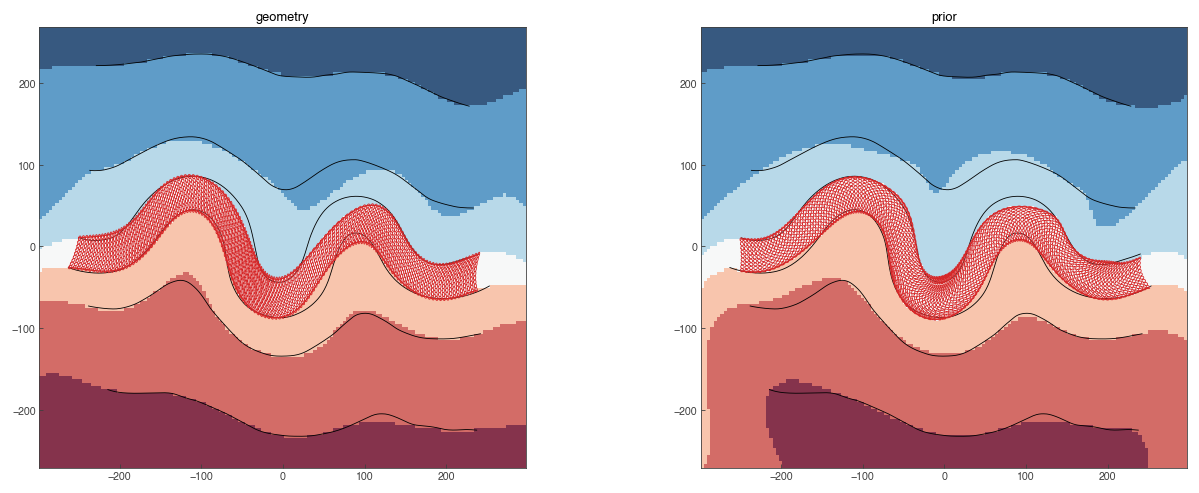

In [5]:
def ellipses(ax, centres, B, scale=2.0, **kw):
    evals, evecs = np.linalg.eigh(B)
    q = np.sqrt(evals[:, 1] / evals[:, 0])
    t = np.linspace(0, 2 * np.pi, 40)
    for c, f, qq in zip(centres, evecs, q):
        e = c[:, None] + scale * (f * np.array([qq ** -0.5, qq ** 0.5])) @ np.stack([np.cos(t), np.sin(t)])
        ax.plot(*e, **kw)


fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, key in zip(axs, fits):
    ax.pcolormesh(G.tformed_axes[0], G.tformed_axes[1], fits[key]["litho"].T, cmap="RdBu", alpha=0.8, shading="auto")
    for tr in horizons_full:
        ax.plot(*tr.T, color="k", lw=0.5)
    for edge in (fits[key]["layer_top"], fits[key]["layer_bottom"]):
        ax.plot(*edge.T, color="C3", lw=0.8)
    ellipses(ax, fits[key]["layer_xy"], fits[key]["B_layer"], color="C3", lw=0.5)
    ax.set_aspect("equal")
    ax.set_title(key)
plt.show()

## Save

In [7]:
np.savez_compressed(
    RES_DIR / "strain_prior.npz",
    x=np.asarray(G.tformed_axes[0]), z=np.asarray(G.tformed_axes[1]),
    layer_shape=np.array([N_ACROSS, N_ALONG]), layer_t=np.linspace(*LAYER_T, N_ACROSS), prior_band=np.array(PRIOR_BAND), test_idx=obs["strain_test_idx"],
    **{f"{key}_{name}": v for key, f in fits.items() for name, v in f.items()},
)
print("wrote", RES_DIR / "strain_prior.npz")

wrote results/strain_prior.npz
